<a href="https://colab.research.google.com/github/sameerc1234/Data_Visualization_lab/blob/main/program3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

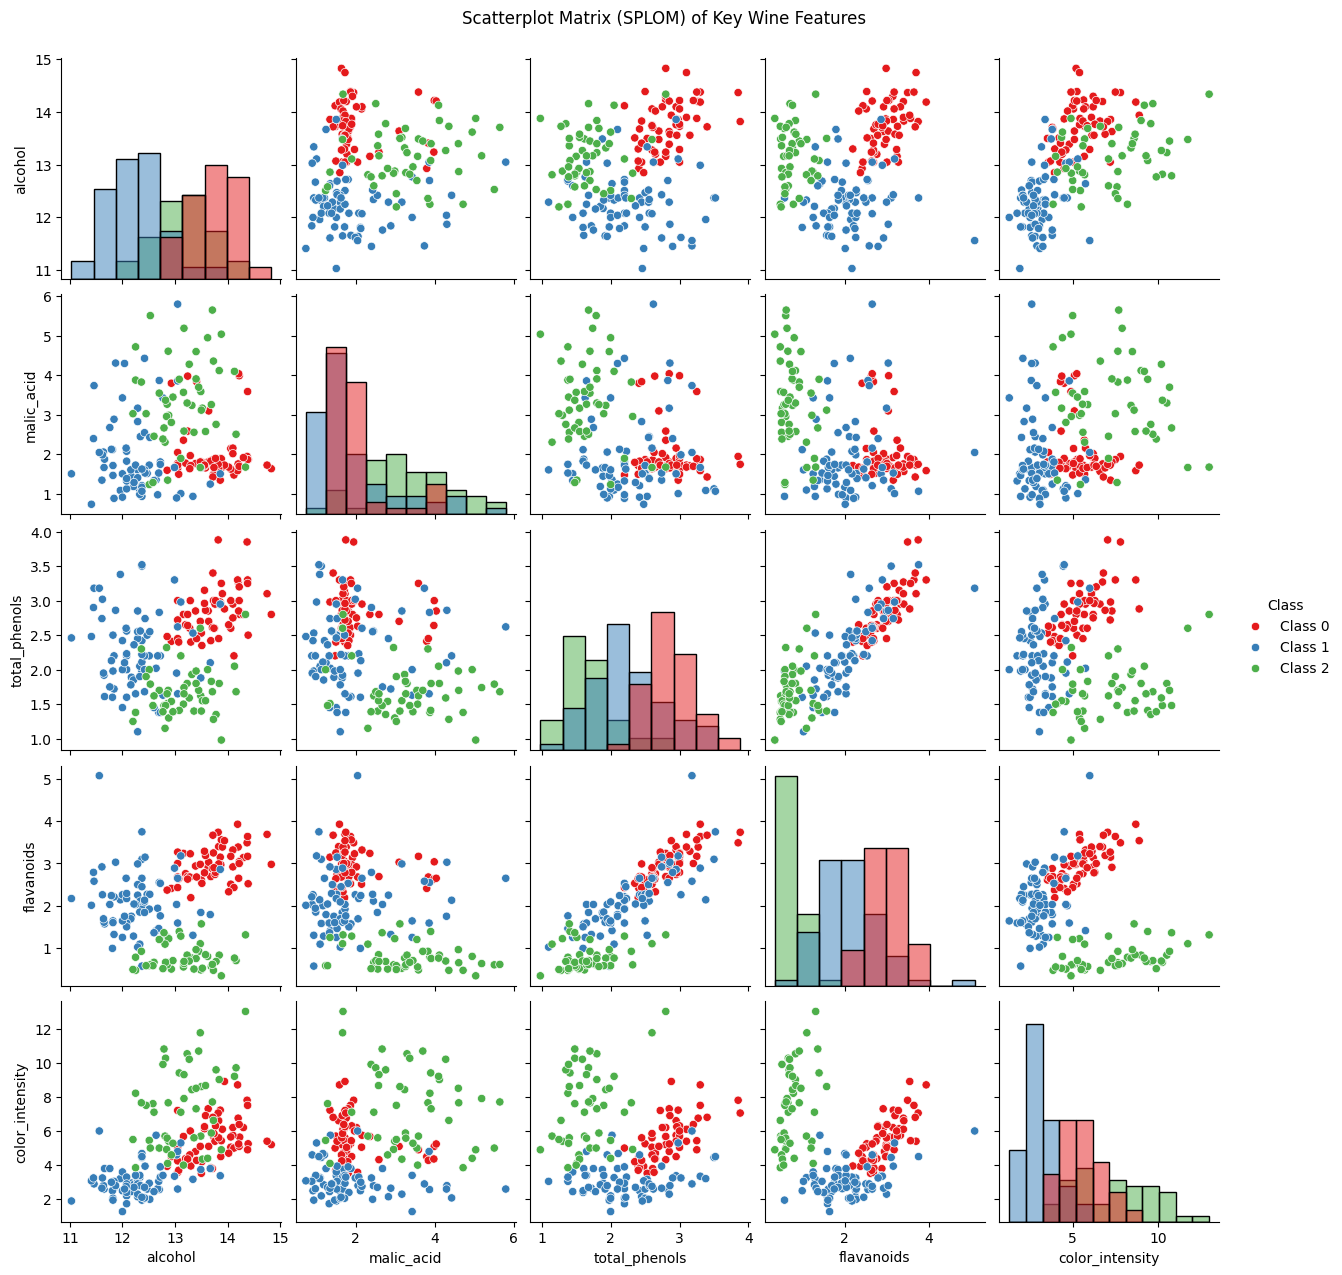

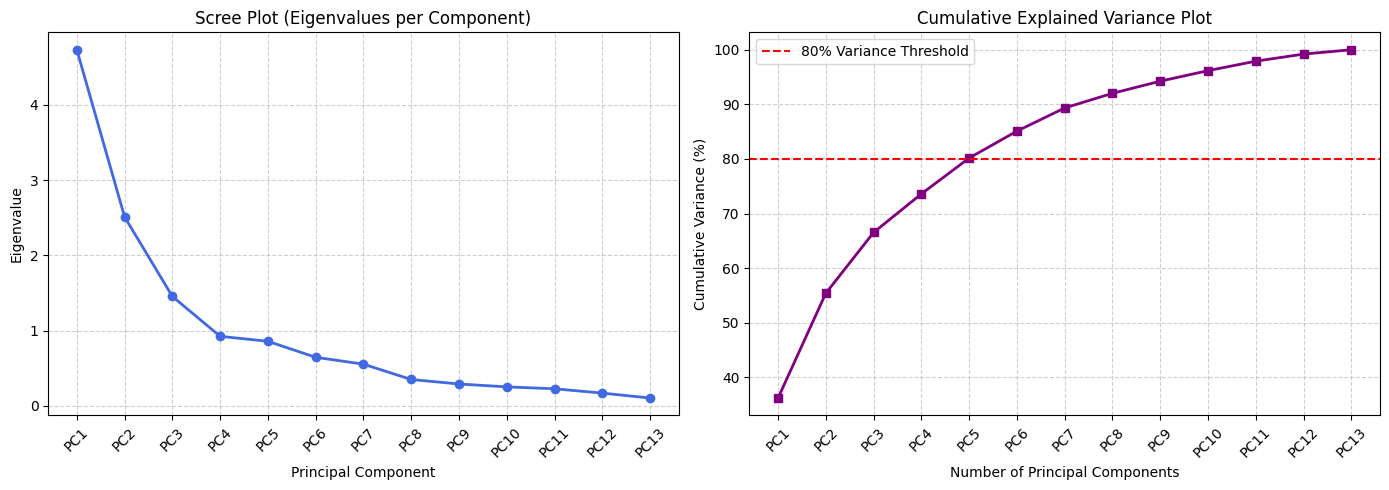

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA

# 1. Load the High-Dimensional Dataset (Wine: 178 samples, 13 features, 3 classes)
wine = load_wine()
df = pd.DataFrame(wine.data, columns=wine.feature_names)
df['Target'] = wine.target
df['Class'] = df['Target'].map({0: 'Class 0', 1: 'Class 1', 2: 'Class 2'})

# ==========================================
# 2. PARALLEL COORDINATES PLOT (PCP)
# ==========================================
# Normalize features to [0, 1] so different scales align on vertical axes
scaler_mm = MinMaxScaler()
df_norm = pd.DataFrame(scaler_mm.fit_transform(wine.data), columns=wine.feature_names)
df_norm['Target'] = wine.target

selected_features = [
    'alcohol', 'malic_acid', 'ash', 'magnesium',
    'total_phenols', 'flavanoids', 'color_intensity', 'hue', 'proline'
]

fig_pcp = px.parallel_coordinates(
    df_norm,
    dimensions=selected_features,
    color='Target',
    color_continuous_scale=px.colors.diverging.Tealrose,
    title='Parallel Coordinates Plot (Normalized Wine Features)'
)
fig_pcp.show()

# ==========================================
# 3. SCATTERPLOT MATRIX (SPLOM)
# ==========================================
splom_features = ['alcohol', 'malic_acid', 'total_phenols', 'flavanoids', 'color_intensity', 'Class']
sns.pairplot(df[splom_features], hue='Class', palette='Set1', diag_kind='hist')
plt.suptitle('Scatterplot Matrix (SPLOM) of Key Wine Features', y=1.02)
plt.show()

# ==========================================
# 4. PERFORM PCA (STANDARDIZE & DECOMPOSE)
# ==========================================
# Standardize features to zero mean and unit variance
X_scaled = StandardScaler().fit_transform(wine.data)

pca = PCA()
X_pca = pca.fit_transform(X_scaled)

eigenvalues = pca.explained_variance_
explained_var = pca.explained_variance_ratio_ * 100
cum_var = np.cumsum(explained_var)
pc_labels = [f'PC{i}' for i in range(1, len(explained_var) + 1)]

# ==========================================
# 5. SCREE PLOT & CUMULATIVE EXPLAINED VARIANCE
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Scree Plot (Eigenvalues)
ax1.plot(pc_labels, eigenvalues, marker='o', linewidth=2, color='royalblue')
ax1.set_title('Scree Plot (Eigenvalues per Component)')
ax1.set_xlabel('Principal Component')
ax1.set_ylabel('Eigenvalue')
ax1.tick_params(axis='x', rotation=45)
ax1.grid(True, linestyle='--', alpha=0.6)

# Cumulative Explained Variance Plot
ax2.plot(pc_labels, cum_var, marker='s', linewidth=2, color='purple')
ax2.axhline(y=80, color='red', linestyle='--', label='80% Variance Threshold')
ax2.set_title('Cumulative Explained Variance Plot')
ax2.set_xlabel('Number of Principal Components')
ax2.set_ylabel('Cumulative Variance (%)')
ax2.tick_params(axis='x', rotation=45)
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# ==========================================
# 6. CLASS-COLORED 2D & 3D PCA VISUALIZATIONS
# ==========================================
pca_df = pd.DataFrame(X_pca, columns=pc_labels)
pca_df['Class'] = df['Class']

ev1, ev2, ev3 = explained_var[0], explained_var[1], explained_var[2]
cv2, cv3 = cum_var[1], cum_var[2]

# 2D PCA Plot
fig_2d = px.scatter(
    pca_df, x='PC1', y='PC2', color='Class', symbol='Class',
    title=f'2D PCA Projection (Retains {cv2:.2f}% Variance)',
    labels={'PC1': f'PC1 ({ev1:.2f}%)', 'PC2': f'PC2 ({ev2:.2f}%)'},
    template='plotly_white'
)
fig_2d.update_traces(marker=dict(size=9, opacity=0.85))
fig_2d.show()

# 3D PCA Plot
fig_3d = px.scatter_3d(
    pca_df, x='PC1', y='PC2', z='PC3', color='Class', symbol='Class',
    title=f'3D PCA Projection (Retains {cv3:.2f}% Variance)',
    labels={
        'PC1': f'PC1 ({ev1:.2f}%)',
        'PC2': f'PC2 ({ev2:.2f}%)',
        'PC3': f'PC3 ({ev3:.2f}%)'
    },
    template='plotly_white'
)
fig_3d.update_traces(marker=dict(size=6, opacity=0.85))
fig_3d.show()
